In [31]:

import pandas as pd
df = pd.read_csv("car_fuel_efficiency_2026.csv")
df.isnull().sum()


model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [32]:
df = df.fillna(0)
df.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

In [33]:
from sklearn.model_selection import train_test_split


df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split( df_full_train, test_size=0.25, random_state=1)
3*len(df_test),len(df_train),3*len(df_val)

(6000, 6000, 6000)

In [34]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2011,USA,Gasoline,Front-wheel drive,4,2370,6,284.0,4280,19.0,30.8
1,2012,USA,Diesel,All-wheel drive,3,2460,6,288.0,4580,18.8,29.7
2,1985,Europe,Gasoline,All-wheel drive,3,2070,6,230.0,4150,20.6,27.6
3,2005,Europe,Diesel,Front-wheel drive,5,2050,5,249.0,4120,0.0,33.7
4,2004,Asia,Gasoline,Front-wheel drive,2,2160,6,241.0,4020,17.9,29.3
...,...,...,...,...,...,...,...,...,...,...,...
5995,1988,Asia,Gasoline,Rear-wheel drive,2,2290,6,235.0,4110,17.9,29.3
5996,2009,Asia,Gasoline,Rear-wheel drive,3,2400,6,245.0,4460,17.5,28.8
5997,2012,Asia,Gasoline,Front-wheel drive,3,2510,6,271.0,4440,19.1,30.7
5998,2003,Europe,Gasoline,All-wheel drive,4,1900,5,211.0,4000,19.4,32.1


In [35]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [36]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import export_text
train_dicts = df_train.to_dict(orient='records')
train_dicts[:2] # each row is a dict

[{'model_year': 2011,
  'origin': 'USA',
  'fuel_type': 'Gasoline',
  'drivetrain': 'Front-wheel drive',
  'num_doors': 4,
  'engine_displacement': 2370,
  'num_cylinders': 6,
  'horsepower': 284.0,
  'vehicle_weight': 4280,
  'acceleration': 19.0},
 {'model_year': 2012,
  'origin': 'USA',
  'fuel_type': 'Diesel',
  'drivetrain': 'All-wheel drive',
  'num_doors': 3,
  'engine_displacement': 2460,
  'num_cylinders': 6,
  'horsepower': 288.0,
  'vehicle_weight': 4580,
  'acceleration': 18.8}]

In [37]:
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
X_train

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 60000 stored elements and shape (6000, 16)>

## Question 1

Let's train a decision tree regressor to predict the `fuel_efficiency_mpg` variable. 

* Train a model with `max_depth=1`.


Which original feature is used for splitting the data? If you use
`DictVectorizer`, map a one-hot feature such as `origin=USA` back to its
original column name.


* `'vehicle_weight'`
* `'model_year'`
* `'origin'`
* `'fuel_type'`


In [38]:
from sklearn.metrics import mean_squared_error
model = DecisionTreeRegressor(max_depth=1, random_state=1)
model.fit(X_train, y_train)
val_dicts = df_val.to_dict(orient='records')

In [39]:
print(export_text(model, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



##### Answer Question 1: model_year

## Question 2

Train a random forest regressor with these parameters:

* `n_estimators=10`
* `random_state=1`
* `n_jobs=-1` (optional - to make training faster)


What's the RMSE of this model on the validation data?

* 0.1837
* 1.837
* 18.37
* 183.7


In [40]:
from sklearn.ensemble import RandomForestRegressor
import numpy as np
rf = RandomForestRegressor(n_estimators=10, random_state=1,n_jobs=-1)
rf.fit(X_train, y_train)
val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)
# 5. Make predictions
y_pred = rf.predict(X_val)

# 6. Evaluate performance
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_val, y_pred)))


Root Mean Squared Error: 1.8332197358745626


#### Answer Question 2: Root Mean Squared Error: 1.8332197358745626

# Question 3

Now let's experiment with the `n_estimators` parameter

* Try these values of this parameter: `[10, 50, 100, 150]`.
* Set `random_state` to `1`.
* Evaluate the model on the validation dataset.


Which value gives the lowest validation RMSE? Consider 3 decimal places for
calculating the answer.

- 10
- 50
- 100
- 150

In [41]:
import matplotlib.pyplot as plt

scores = []

for n in [10, 50, 100, 150]:
    
    rf = RandomForestRegressor(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    
    scores.append((n, rmse))
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'rmse'])


In [13]:
df_scores.head()

,n_estimators,rmse
0,10,1.833220
1,50,1.773988
2,100,1.769786
3,150,1.769198


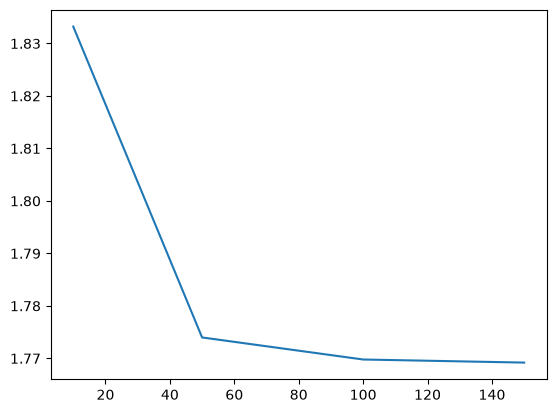

In [14]:
plt.plot(df_scores.n_estimators, df_scores.rmse)


### Answer Question 3: 150

## Question 4

Let's select the best `max_depth`:

* Try different values of `max_depth`: `[10, 15, 20, 25]`
* For each of these values,
  * try different values of `n_estimators` from `[10, 50, 100, 150]`
  * calculate the mean RMSE 
* Fix the random seed: `random_state=1`


What's the best `max_depth`, using the mean RMSE?

* 10
* 15
* 20
* 25


In [1]:

scores = []

for d in [10, 15, 20, 25]:
    for n in [10]: #[10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))

        scores.append((d, n, rmse))
columns = ['max_depth', 'n_estimators', 'rmse']
df_scores = pd.DataFrame(scores, columns=columns)  


NameError: name 'RandomForestRegressor' is not defined

In [42]:
import matplotlib.pyplot as plt

for d in [10, 15, 20, 25]:
    df_subset = df_scores[df_scores.max_depth == d]
    
    plt.plot(df_subset.n_estimators, df_subset.rmse,
             label='max_depth=%d' % d)

plt.legend()

AttributeError: 'DataFrame' object has no attribute 'max_depth'

### Answer Question 4 : 20

# Question 5

We can extract feature importance information from tree-based models. 

At each step of the decision tree learning algorithm, it finds the best split. 
When doing it, we can calculate "gain" - the reduction in impurity before and after the split. 
This gain is quite useful in understanding what are the important features for tree-based models.

In Scikit-Learn, tree-based models contain this information in the
[`feature_importances_`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor.feature_importances_)
field. 

For this homework question, we'll find the most important feature:

* Train the model with these parameters:
  * `n_estimators=10`,
  * `max_depth=20`,
  * `random_state=1`,
  * `n_jobs=-1` (optional)
* Get the feature importance information from this model


What's the most important feature (among these 4)? 

* `vehicle_weight`
*	`horsepower`
* `acceleration`
* `engine_displacement`	

In [15]:
from sklearn.ensemble import RandomForestRegressor  # or RandomForestClassifier
import pandas as pd


rf = RandomForestRegressor(
    n_estimators=10,
    max_depth=20,
    random_state=1,
    n_jobs=-1
)

rf.fit(X_train, y_train)
importances = rf.feature_importances_

# Get feature names from DictVectorizer
feature_names = dv.get_feature_names_out() 

# Combine feature names with importances
importances_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
})

# Sort by importance descending
importances_df = importances_df.sort_values(by='importance', ascending=False)

importances_df


,feature,importance
9,model_year,0.296107
15,vehicle_weight,0.203313
6,fuel_type=Gasoline,0.160712
8,horsepower,0.078271
4,engine_displacement,0.061281
0,acceleration,0.054998
14,origin=USA,0.042152
2,drivetrain=Front-wheel drive,0.020062
11,num_doors,0.019401
5,fuel_type=Diesel,0.016571


### Answer Question 5:  vehicle_weight

## Question 6

Now let's train an XGBoost model! For this question, we'll tune the `eta` parameter:

* Install XGBoost
* Create DMatrix for train and validation
* Create a watchlist
* Train a model with these parameters for 100 rounds:

```
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}
```

Now change `eta` from `0.3` to `0.1`.

Which eta leads to the best RMSE score on the validation dataset?

* 0.3
* 0.1
* Both give equal value

In [20]:
import xgboost as xgb
import numpy as np
from sklearn.metrics import mean_squared_error

from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
dv = DictVectorizer(sparse=False)
train_dicts = df_train.fillna(0).to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
watchlist = [(dtrain, 'train'), (dval, 'val')]
scores = {}
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

In [21]:
%%capture output
model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                  evals=watchlist)

In [22]:
import matplotlib.pyplot as plt

def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results
df_score = parse_xgb_output(output)  
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key


'eta=0.3'

In [23]:
df_score

,num_iter,train_rmse,val_rmse
0,0,2.40653,2.46782
1,1,2.07098,2.15784
2,2,1.86454,1.97398
3,3,1.73360,1.86662
4,4,1.65059,1.80312
...,...,...,...
95,95,0.91805,1.82544
96,96,0.91629,1.82554
97,97,0.91360,1.82506
98,98,0.90760,1.82575


In [24]:
y_pred = model.predict(dval)
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_val, y_pred)))


Root Mean Squared Error: 1.8264579799904583


In [25]:
xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}


In [26]:
%%capture output
model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                  evals=watchlist)

In [27]:
df_score = parse_xgb_output(output)  
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.1'

In [28]:
df_score

,num_iter,train_rmse,val_rmse
0,0,2.74739,2.78635
1,1,2.58527,2.63162
2,2,2.44540,2.50036
3,3,2.32187,2.38568
4,4,2.21445,2.28765
...,...,...,...
95,95,1.32292,1.72324
96,96,1.32262,1.72341
97,97,1.31920,1.72354
98,98,1.31455,1.72414


In [29]:
y_pred = model.predict(dval)
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_val, y_pred)))


Root Mean Squared Error: 1.724810059827976


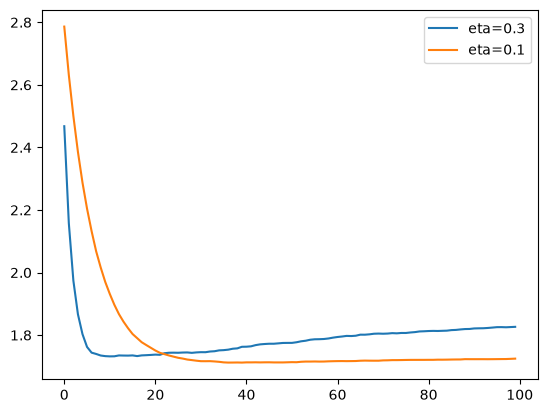

In [30]:
for eta, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_rmse, label=eta)

plt.legend()

### Answer Question 6: eta=0.1